# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Chest X-Ray Pneumonia Classification | Xception Transfer Learning and Fine-Tuning</p>

> **Source note:** This notebook is based on the public Kaggle notebook [*Chest X-Ray | Xception | 94%*](https://www.kaggle.com/code/abdmental01/chest-x-ray-xception-94) by Muhammad_Abdullah (abdmental01). The data loading and visualization sections are adapted from it. The original trains only a new classification head on a fully frozen Xception base. My changes and additions:
>
> - A different head configuration (higher dropout), a lower learning rate and shorter early stopping.
> - Partial unfreezing of the base network and a second **fine-tuning** stage (last 30 layers, learning rate 1e-5).
> - Class-aware augmentation applied only to the `NORMAL` class.
> - Saving of both models and an inference script for the MIORA service.
>
> **Dataset:** Chest X-Ray Images (Pneumonia), classes `NORMAL` and `PNEUMONIA`.


# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Importing Libraries</p>

In [ ]:
#Import Os and Basis Libraries
import cv2
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#Matplot Images
import matplotlib.image as mpimg
# Tensflor and Keras Layer and Model and Optimize and Loss
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import *
from tensorflow.keras.losses import BinaryCrossentropy
#Kernel Intilizer
from sklearn.preprocessing import LabelEncoder
# import tensorflow_hub as hub
from tensorflow.keras.optimizers import Adam , Adamax
#PreTrained Model
from tensorflow.keras.applications import *
#Early Stopping
from tensorflow.keras.callbacks import EarlyStopping
# Warnings Remove
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/chest_xray(1).zip"
extract_path = "/content/chest_xray"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Load Data</p>

In [ ]:
# Directory containing the "Train" folder
directory = "/content/chest_xray/chest_xray/train"

filepath =[]
label = []

folds = os.listdir(directory)

for fold in folds:
    f_path = os.path.join(directory , fold)

    imgs = os.listdir(f_path)

    for img in imgs:

        img_path = os.path.join(f_path , img)
        filepath.append(img_path)
        label.append(fold)

#Concat data paths with labels
file_path_series = pd.Series(filepath , name= 'filepath')
Label_path_series = pd.Series(label , name = 'label')
df_train = pd.concat([file_path_series ,Label_path_series ] , axis = 1)

In [ ]:
# Head
df_train

,filepath,label
0,/content/chest_xray/chest_xray/train/NORMAL/NO...,NORMAL
1,/content/chest_xray/chest_xray/train/NORMAL/NO...,NORMAL
2,/content/chest_xray/chest_xray/train/NORMAL/NO...,NORMAL
3,/content/chest_xray/chest_xray/train/NORMAL/NO...,NORMAL
4,/content/chest_xray/chest_xray/train/NORMAL/NO...,NORMAL
...,...,...
5227,/content/chest_xray/chest_xray/train/PNEUMONIA...,PNEUMONIA
5228,/content/chest_xray/chest_xray/train/PNEUMONIA...,PNEUMONIA
5229,/content/chest_xray/chest_xray/train/PNEUMONIA...,PNEUMONIA
5230,/content/chest_xray/chest_xray/train/PNEUMONIA...,PNEUMONIA


In [ ]:
# Directory containing the "Train" folder
directory = "/content/chest_xray/chest_xray/test"

filepath =[]
label = []

folds = os.listdir(directory)

for fold in folds:
    f_path = os.path.join(directory , fold)

    imgs = os.listdir(f_path)

    for img in imgs:

        img_path = os.path.join(f_path , img)
        filepath.append(img_path)
        label.append(fold)

#Concat data paths with labels
file_path_series = pd.Series(filepath , name= 'filepath')
Label_path_series = pd.Series(label , name = 'label')
df_test = pd.concat([file_path_series ,Label_path_series ] , axis = 1)

In [ ]:
# Head
df_test.sample(5)

,filepath,label
307,/content/chest_xray/chest_xray/test/PNEUMONIA/...,PNEUMONIA
566,/content/chest_xray/chest_xray/test/PNEUMONIA/...,PNEUMONIA
167,/content/chest_xray/chest_xray/test/NORMAL/NOR...,NORMAL
613,/content/chest_xray/chest_xray/test/PNEUMONIA/...,PNEUMONIA
178,/content/chest_xray/chest_xray/test/NORMAL/NOR...,NORMAL


In [ ]:
# Shape
print(f"The shape of The Train data is: {df_train.shape}")
print(f"The shape of The Test data is: {df_test.shape}")

The shape of The Train data is: (5232, 2)
The shape of The Test data is: (624, 2)


# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Making Train Test And Validation Datasets</p>

In [ ]:
#Data_Dir
data_dir = '/content/chest_xray/chest_xray/train'
test_dir = '/content/chest_xray/chest_xray/test'

IMAGE_SIZE = (256,256)

print('Training Images:')
# Creating the training dataset
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.1,
    subset='training',
    seed=456,
    image_size=IMAGE_SIZE,
    batch_size=32
)

#Testing  Data
print('Validation Images:')
validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.1,
    subset='validation',
    seed=456,
    image_size=IMAGE_SIZE,
    batch_size=32)

print('Testing Images:')
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=32)

Training Images:
Found 5232 files belonging to 2 classes.
Using 4709 files for training.
Validation Images:
Found 5232 files belonging to 2 classes.
Using 523 files for validation.
Testing Images:
Found 624 files belonging to 2 classes.


In [ ]:
# class_names'i augmentasyon öncesi al
class_names = train_ds_raw.class_names
print("Sınıf sıralaması:", class_names)

Sınıf sıralaması: ['NORMAL', 'PNEUMONIA']


In [ ]:
def augment_if_normal_batch(images, labels):
    images = tf.image.convert_image_dtype(images, tf.float32)

    # Hafif augmentasyon tanımı
    def light_augment(img):
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_brightness(img, max_delta=0.05)  # azaltıldı
        img = tf.image.random_contrast(img, lower=0.95, upper=1.05)  # azaltıldı
        return img

    # Tüm batch için augment edilmiş kopya
    augmented_images = tf.map_fn(light_augment, images)

    # NORMAL sınıfı için maske
    is_normal = tf.equal(labels, 0)
    is_normal = tf.reshape(is_normal, (-1, 1, 1, 1))

    # Sadece NORMAL olanları değiştir
    final_images = tf.where(is_normal, augmented_images, images)

    return final_images, labels


In [ ]:
train_ds = train_ds_raw.map(augment_if_normal_batch, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)


# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Encoding Labels</p>


In [ ]:
# Augmentasyon öncesi class_names zaten alınmıştı
class_labels = class_names  # Örn: ['NORMAL', 'PNEUMONIA']

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(class_labels)


# Encode Labels

# Define your class labels
class_labels = ['NORMAL', 'PNEUMONIA']

# Instantiate LabelEncoder
label_encoder = LabelEncoder()

# Fit label encoder on the class labels
label_encoder.fit(class_labels)

label_encoder.fit(class_names)


LabelEncoder()

In [ ]:
# Shape of the dataset
for image_batch, labels_batch in train_ds:
    print("Shape of X_train: ", image_batch.shape)
    print("Shape of y_train: ", labels_batch.shape)
    break

Shape of X_train:  (32, 256, 256, 3)
Shape of y_train:  (32,)


# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Normalizing Pixel Value</p>


In [ ]:
# Normalizing Pixel Values

# Train Data
train_ds = train_ds.map(lambda x, y: (x / 255.0, y))
# Val Data
validation_ds = validation_ds.map(lambda x, y: (x / 255.0, y))
# Test Data
test_ds = test_ds.map(lambda x, y: (x / 255.0, y))

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Visual Count of Train Label</p>


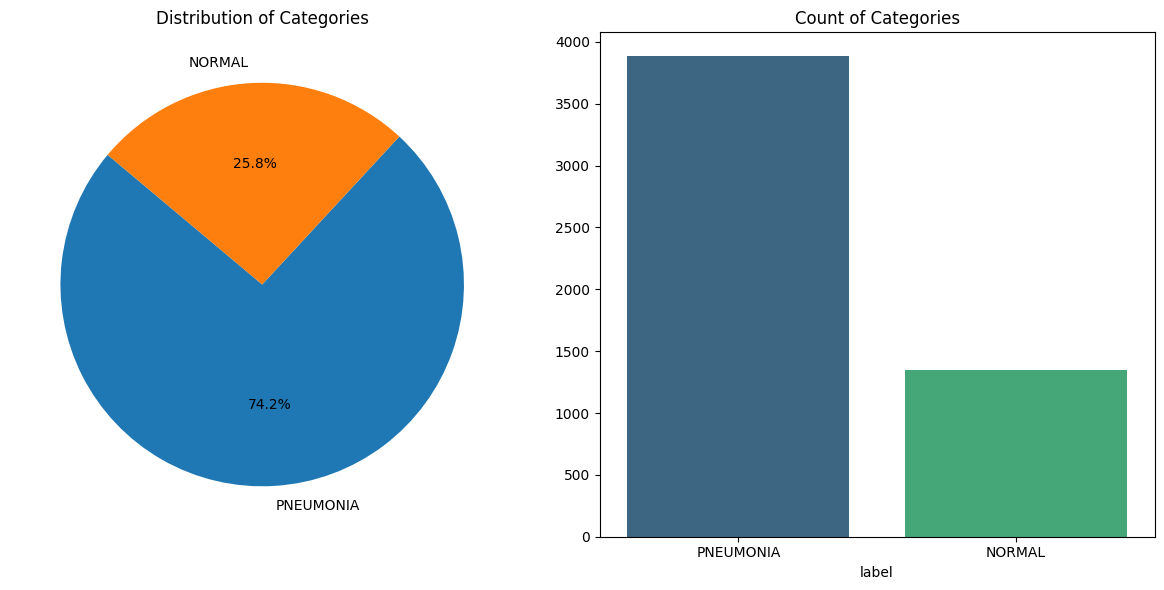

In [ ]:
# Count the occurrences of each category in the 'category' column
count = df_train['label'].value_counts()

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6), facecolor='white')

# Plot pie chart on the first subplot
palette = sns.color_palette("viridis")
sns.set_palette(palette)
axs[0].pie(count, labels=count.index, autopct='%1.1f%%', startangle=140)
axs[0].set_title('Distribution of Categories')

# Plot bar chart on the second subplot
sns.barplot(x=count.index, y=count.values, ax=axs[1], palette="viridis")
axs[1].set_title('Count of Categories')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Visual Count of Test Label</p>


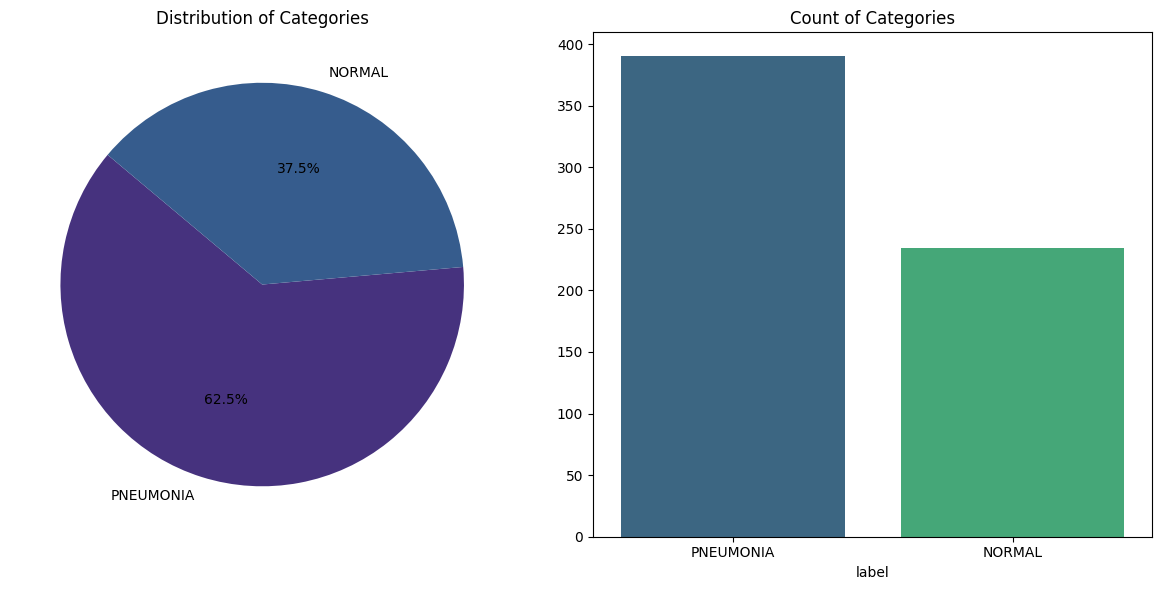

In [ ]:
# Count the occurrences of each category in the 'category' column
count = df_test['label'].value_counts()

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6), facecolor='white')

# Plot pie chart on the first subplot
palette = sns.color_palette("viridis")
sns.set_palette(palette)
axs[0].pie(count, labels=count.index, autopct='%1.1f%%', startangle=140)
axs[0].set_title('Distribution of Categories')

# Plot bar chart on the second subplot
sns.barplot(x=count.index, y=count.values, ax=axs[1], palette="viridis")
axs[1].set_title('Count of Categories')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Visualizing Train Images</p>

In [ ]:
def visualize_images(path, num_images=5):
    # Get a list of image filenames in the specified path
    image_filenames = os.listdir(path)

    # Limit the number of images to visualize if there are more than num_images
    num_images = min(num_images, len(image_filenames))

    # Create a figure and axis object to display images
    fig, axes = plt.subplots(1, num_images, figsize=(15, 3),facecolor='white')

    # Iterate over the selected images and display them
    for i, image_filename in enumerate(image_filenames[:num_images]):
        # Load the image using Matplotlib
        image_path = os.path.join(path, image_filename)
        image = mpimg.imread(image_path)

        # Display the image
        axes[i].imshow(image)
        axes[i].axis('off')  # Turn off axis
        axes[i].set_title(image_filename)  # Set image filename as title

    # Adjust layout and display the figure
    plt.tight_layout()
    plt.show()

###### **<h1 align="center"><span style="color:#6A5ACD;">NORMAL Images</span>**

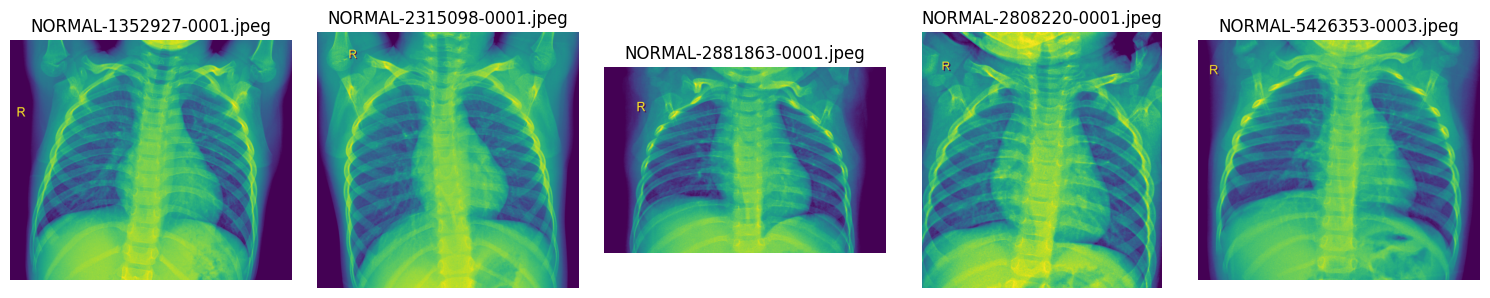

In [ ]:
# Specify the path containing the images to visualize
path_to_visualize = "/content/chest_xray/chest_xray/train/NORMAL"

# Visualize some images from the specified path
visualize_images(path_to_visualize, num_images=5)

###### **<h1 align="center"><span style="color:#6A5ACD;">PNEUMONIA Images</span>**

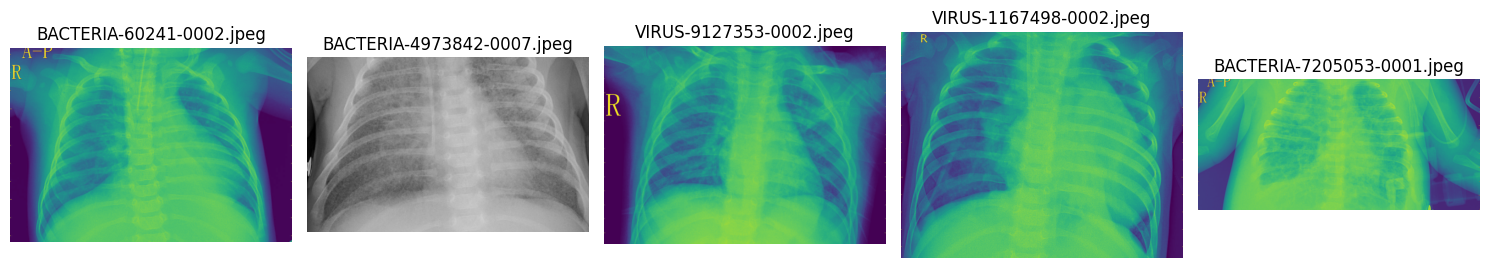

In [ ]:
# Specify the path containing the images to visualize
path_to_visualize = "/content/chest_xray/chest_xray/train/PNEUMONIA"

# Visualize some images from the specified path
visualize_images(path_to_visualize, num_images=5)

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Model Building</p>

###### **<h1 align="center"><span style="color:#6A5ACD;">Transfer Learning and Fine-Tuning</span>**

The model uses an Xception network pre-trained on ImageNet as a feature extractor, with a new classification head for the binary task (NORMAL vs PNEUMONIA). Training has two stages:

1. **Head training:** the base network is frozen except for its last 5 layers, and the new head (BatchNormalization, Dropout 0.6, Dense 220, Dropout 0.35, Dense 60, sigmoid output) is trained with the Adamax optimizer at a learning rate of 1e-4 for up to 10 epochs. Early stopping on validation loss (patience 3) is used.
2. **Fine-tuning:** the last 30 layers of the base network are unfrozen and trained with a lower learning rate (1e-5) for up to 7 epochs, so the pre-trained features adapt to chest X-rays without being overwritten.

Light augmentation (random horizontal flip, small brightness and contrast changes) is applied only to images of the `NORMAL` class, which is the smaller class in this dataset. 10% of the training folder is held out for validation, and the separate `test` folder is used for testing.


Model definition used here:

1. `Xception(weights='imagenet', include_top=False, pooling='avg', input_shape=(256, 256, 3))` loads the ImageNet pre-trained base without its classifier and with global average pooling.
2. All base layers are frozen except the last 5, so the first training stage mostly adapts the new head.
3. The head is `BatchNormalization`, `Dropout(0.6)`, `Dense(220, relu)`, `Dropout(0.35)`, `Dense(60, relu)` and `Dense(1, sigmoid)` for binary classification.
4. The model is compiled with Adamax (learning rate 1e-4), binary cross-entropy loss and accuracy as the metric.


In [ ]:
# Load the Xception base model without the top (classification) layer
base_model = Xception(weights='imagenet', include_top=False, pooling='avg', input_shape=(256, 256, 3))

# Freeze the layers in the base model
base_model.trainable = True

# Sadece son 30 katmanı eğitime aç
for layer in base_model.layers[:-5]:
    layer.trainable = False


model = Sequential()
model.add(base_model)
model.add(BatchNormalization())
model.add(Dropout(0.6))  # artırıldı
model.add(Dense(220, activation='relu'))
model.add(Dropout(0.35))  # artırıldı
model.add(Dense(60, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# Compile
model.compile(optimizer=Adamax(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 220)            │       450,780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 220)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 60)             │        13,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            61 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,333,773 (81.38 MB)

 Trainable params: 3,631,845 (13.85 MB)

 Non-trainable params: 17,701,928 (67.53 MB)

###### **<h1 align="center"><span style="color:#6A5ACD;">Compile and Fitting</span>**

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)



#Early_Stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

#Fitting Model
history = model.fit(train_ds,
                    epochs=10,
                    validation_data=validation_ds,
                    callbacks=[early_stopping])


# Modeli kaydet
model.save('xception_model.h5')
print("Model başarıyla kaydedildi!")


Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 118s 532ms/step - accuracy: 0.8439 - loss: 0.3575 - val_accuracy: 0.9293 - val_loss: 0.3625
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 75s 314ms/step - accuracy: 0.9013 - loss: 0.2378 - val_accuracy: 0.9350 - val_loss: 0.2287
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 83s 320ms/step - accuracy: 0.9221 - loss: 0.1915 - val_accuracy: 0.9407 - val_loss: 0.1746
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 46s 307ms/step - accuracy: 0.9274 - loss: 0.1822 - val_accuracy: 0.9426 - val_loss: 0.1565
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 45s 304ms/step - accuracy: 0.9384 - loss: 0.1603 - val_accuracy: 0.9388 - val_loss: 0.1525
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 84s 315ms/step - accuracy: 0.9422 - loss: 0.1522 - val_accuracy: 0.9388 - val_loss: 0.1463
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 46s 307ms/step - accuracy: 0.9414 - loss: 0.1483 - val_accuracy: 0.9465 - val_loss: 0.1431
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 46s 307ms/step - accuracy: 0.9412 - loss: 

Model başarıyla kaydedildi!


In [ ]:
# 🔁 Fine-Tuning: Daha fazla katmanı eğitime aç
for layer in base_model.layers[-30:]:  # Örneğin son 30 katmanı aç
    layer.trainable = True

# ✅ Modeli yeniden derle (daha düşük learning rate ile)
model.compile(optimizer=Adamax(learning_rate=1e-5),
              loss='binary_crossentropy',
              metrics=['accuracy'])

# ✅ Fine-tuning eğitimi başlat
fine_tune_history = model.fit(train_ds,
                              validation_data=validation_ds,
                              epochs=7,
                              callbacks=[early_stopping])

# ✅ Yeni modeli kaydet
model.save("xception_model_finetuned.h5")
print("Fine-tuning uygulanmış model başarıyla kaydedildi.")

Epoch 1/7
148/148 ━━━━━━━━━━━━━━━━━━━━ 84s 411ms/step - accuracy: 0.9017 - loss: 0.2466 - val_accuracy: 0.9293 - val_loss: 0.1993
Epoch 2/7
148/148 ━━━━━━━━━━━━━━━━━━━━ 48s 323ms/step - accuracy: 0.9165 - loss: 0.1942 - val_accuracy: 0.9484 - val_loss: 0.1452
Epoch 3/7
148/148 ━━━━━━━━━━━━━━━━━━━━ 45s 305ms/step - accuracy: 0.9225 - loss: 0.1864 - val_accuracy: 0.9426 - val_loss: 0.1665


Fine-tuning uygulanmış model başarıyla kaydedildi.


In [ ]:
print("Fine-tuning sonrası doğruluk:")
print("Son eğitim doğruluğu:", fine_tune_history.history['accuracy'][-1])
print("Son doğrulama doğruluğu:", fine_tune_history.history['val_accuracy'][-1])

Fine-tuning sonrası doğruluk:
Son eğitim doğruluğu: 0.9224888682365417
Son doğrulama doğruluğu: 0.942638635635376


###### **<h1 align="center"><span style="color:#6A5ACD;">Val Loss and Accuracy</span>**

In [ ]:
# Evaluate the model on the validation dataset
validation_loss, validation_accuracy = model.evaluate(validation_ds)

# Print the validation loss and accuracy
print("Validation Loss:", validation_loss)
print("Validation Accuracy:", validation_accuracy)

17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.9293 - loss: 0.1993
Validation Loss: 0.19933530688285828
Validation Accuracy: 0.9292542934417725


In [ ]:
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-darkgrid')

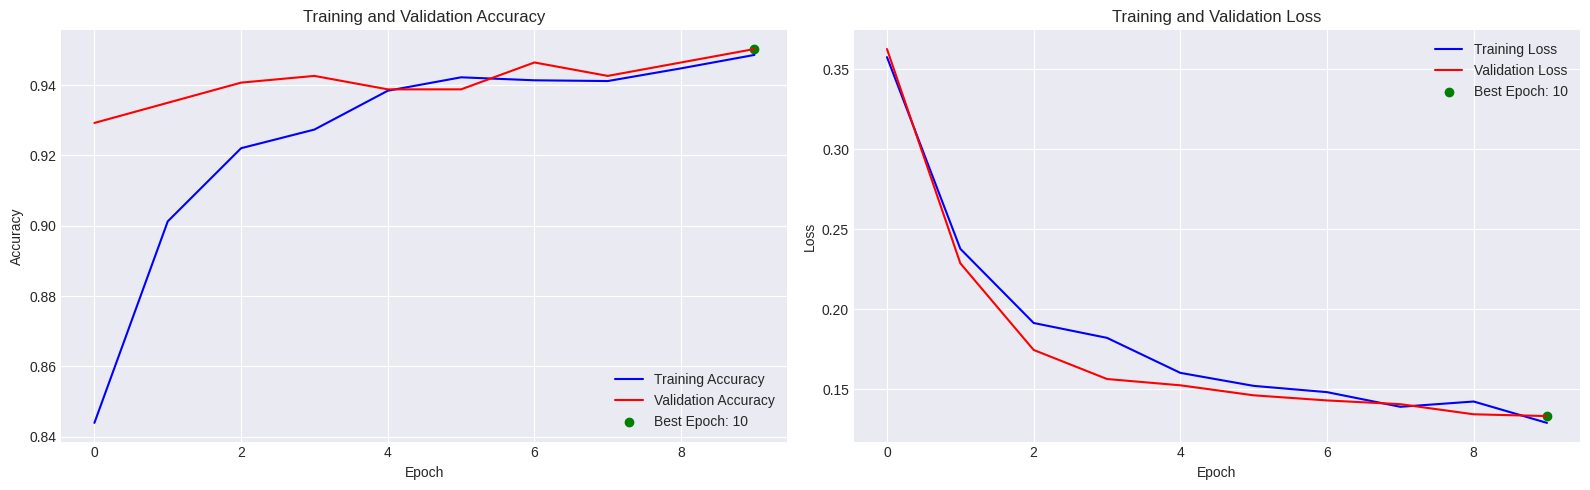

In [ ]:
# Get the epoch with the highest validation accuracy
best_epoch = history.history['val_accuracy'].index(max(history.history['val_accuracy'])) + 1

# Set the background style
plt.style.use('seaborn-v0_8-darkgrid')

# Create a subplot with 1 row and 2 columns
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# Plot training and validation accuracy
axs[0].plot(history.history['accuracy'], label='Training Accuracy', color='blue')
axs[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='red')
axs[0].scatter(best_epoch - 1, history.history['val_accuracy'][best_epoch - 1], color='green', label=f'Best Epoch: {best_epoch}')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy')
axs[0].set_title('Training and Validation Accuracy')
axs[0].legend()

# Plot training and validation loss
axs[1].plot(history.history['loss'], label='Training Loss', color='blue')
axs[1].plot(history.history['val_loss'], label='Validation Loss', color='red')
axs[1].scatter(best_epoch - 1, history.history['val_loss'][best_epoch - 1], color='green',label=f'Best Epoch: {best_epoch}')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].set_title('Training and Validation Loss')
axs[1].legend()

plt.tight_layout()
plt.show()

# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Test Set Evaluation</p>

> **Note on the results:** This notebook is run on the public Kaggle *Chest X-Ray Images (Pneumonia)* dataset. Its `test` folder differs in distribution from the training data and is harder than a validation split taken from the training folder. The 93% accuracy reported in the MIORA paper was measured on the project's own dataset, which is not included here, so the numbers are not directly comparable.

The model is evaluated on the separate `test` folder with the same preprocessing as training (pixel values divided by 255 exactly once, no shuffling so labels and predictions line up).

Found 624 files belonging to 2 classes.
Class order (0, 1): ['NORMAL', 'PNEUMONIA']
20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step
Test accuracy: 0.7885
              precision    recall  f1-score   support

      NORMAL      0.981     0.444     0.612       234
   PNEUMONIA      0.749     0.995     0.855       390

    accuracy                          0.788       624
   macro avg      0.865     0.720     0.733       624
weighted avg      0.836     0.788     0.764       624



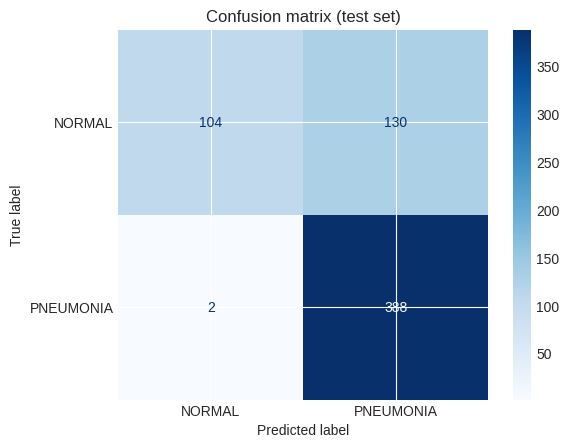

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_eval_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/chest_xray/chest_xray/test',
    image_size=IMAGE_SIZE,
    batch_size=32,
    shuffle=False)
print("Class order (0, 1):", test_eval_ds.class_names)   # expected: ['NORMAL', 'PNEUMONIA']
test_eval_ds = test_eval_ds.map(lambda x, y: (x / 255.0, y))   # normalize exactly once

y_true = np.concatenate([y.numpy() for _, y in test_eval_ds])
y_prob = model.predict(test_eval_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print("Test accuracy:", round(float((y_pred == y_true).mean()), 4))
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA'], digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['NORMAL', 'PNEUMONIA']).plot(cmap='Blues')
plt.title('Confusion matrix (test set)')
plt.show()


# <p style="font-family:newtimeroman;font-size:150%;text-align:center;color:#6A5ACD;">Model Predictions</p>

Testing Images:
Found 624 files belonging to 2 classes.


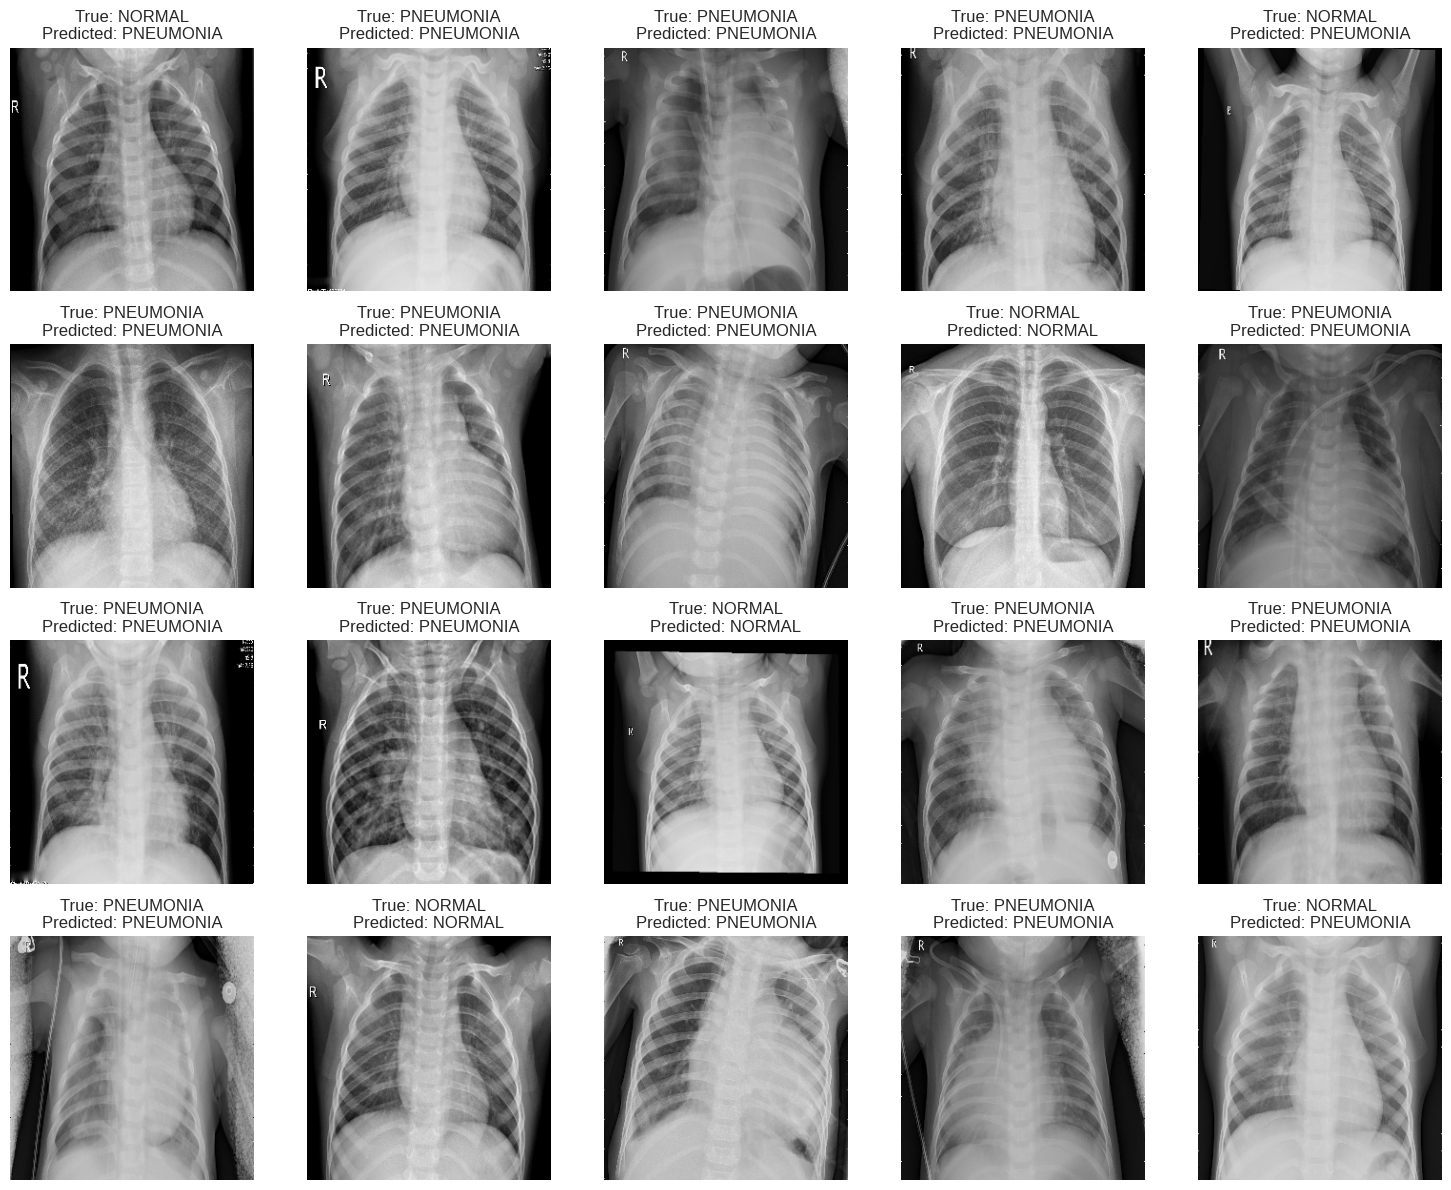

In [ ]:
test_dir = '/content/chest_xray/chest_xray/test'
print('Testing Images:')
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=32)

def plot_images_with_predictions(model, dataset, class_names, num_images=20, num_images_per_row=5):
    """Show random test images with true and predicted labels (sigmoid output, 0 = NORMAL, 1 = PNEUMONIA)."""
    rows = int(np.ceil(num_images / num_images_per_row))
    plt.figure(figsize=(15, 3 * rows))
    shown = 0
    for images, labels in dataset.shuffle(buffer_size=len(dataset), seed=1):
        probs = model.predict(images / 255.0, verbose=0).ravel()  # same normalization as training
        for img, label, prob in zip(images.numpy(), labels.numpy(), probs):
            if shown >= num_images:
                break
            plt.subplot(rows, num_images_per_row, shown + 1)
            plt.imshow(img.astype("uint8"))
            plt.title(f"True: {class_names[int(label)]}\nPredicted: {class_names[int(prob > 0.5)]}")
            plt.axis('off')
            shown += 1
        if shown >= num_images:
            break
    plt.tight_layout()
    plt.show()

plot_images_with_predictions(model, test_ds, class_names, num_images=20)


1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


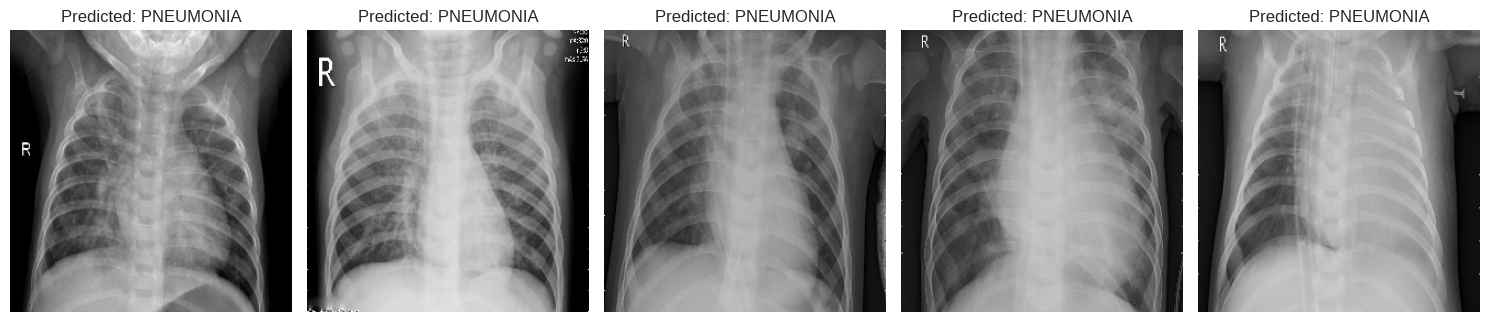

In [ ]:
# Path to the directory containing the images
directory_path = '/content/chest_xray/chest_xray/test/PNEUMONIA/'

# Select N image files from the directory
image_files = os.listdir(directory_path)[:5]

# Create a figure and axes for subplots
fig, axs = plt.subplots(1, len(image_files), figsize=(15, 5))

# Load and preprocess each image, make predictions, and display them using a loop
for i, image_file in enumerate(image_files):
    img_path = os.path.join(directory_path, image_file)
    # Load the image using OpenCV
    img = cv2.imread(img_path)
    # Resize the image to (256, 256)
    img = cv2.resize(img, (256, 256))

    # Normalize pixel values
    img_array = img.astype(np.float32) / 255.0

    # Expand the dimensions to match the input shape expected by the model
    img_array = np.expand_dims(img_array, axis=0)

    # Make predictions
    predictions = model.predict(img_array)
    actual_prediction = (predictions > 0.5).astype(int)

    # Display the image with predicted label
    # Convert BGR to RGB for displaying with matplotlib
    axs[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axs[i].axis('off')
    if actual_prediction[0][0] == 0:
        predicted_label = 'Normal'
    else:
        predicted_label = 'PNEUMONIA'
    axs[i].set_title(f'Predicted: {predicted_label}')

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import json
from tensorflow.keras.models import load_model

# === 1. Fine-tune Edilmiş Modeli Yükle ===
model = load_model('xception_model_finetuned.h5')

# === 2. Görselin Yolunu Belirt ===
# Örnek: Görsel Google Drive'daysa
img_path = "/content/NORMAL2-IM-1427-0001.jpeg"  # kendi görsel yoluna göre düzenle

# Görseli model ile uyumlu hale getir
img = image.load_img(img_path, target_size=(256, 256))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0  # Normalize et (modelin eğitimine göre)

# === 3. Tahmin Yap ===
prediction = model.predict(img_array)

# Tahmin sonucunu yorumla
if prediction[0][0] > 0.5:
    sonuc_text = "HASTALIK VAR"
else:
    sonuc_text = "SAĞLIKLI"

# JSON formatında sonucu hazırla
result = {
    "sonuc": sonuc_text
}

# JSON çıktısı oluştur ve terminale yazdır
result_json = json.dumps(result, indent=4)
print(result_json)
print(prediction[0][0])

# === 4. JSON'u Kaydet (Colab'e veya Drive'a) ===
with open('/content/tahmin_sonucu.json', 'w') as json_file:
    json.dump(result, json_file, indent=4)

print("Sonuç tahmin_sonucu.json dosyasına kaydedildi.")

# === 5. Görseli Göster ===
plt.imshow(img)
plt.title("Tahmin Yapılan Görsel")
plt.axis("off")
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/content/NORMAL2-IM-1427-0001.jpeg'